# 01. Exploratory Data Analysis (EDA)

> **포트폴리오 정리 과정에서 새로 구성한 재현용 노트북(2026)**입니다. 2024년 당시 수행한 분석 원본은 `archive_2024/Original_EDA_and_Baseline.ipynb`에서 확인할 수 있습니다.

**목적:** 건강정보 기반 `health_status` 이진 분류 문제의 데이터 크기, 클래스 비율, 결측치, 주요 수치 변수와 타깃의 관계, Train/Test 분포를 살펴봅니다.

원본 데이터의 `name`은 모델 설명과 시각화에서 제외합니다. 여기서 확인한 *상관관계는 인과관계를 의미하지 않습니다*.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 프로젝트 루트 또는 notebooks/에서 실행할 수 있도록 상대 경로 탐색
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
project_dir = next((p for p in candidates if (p / 'data' / 'train.csv').exists()), None)
if project_dir is None:
    raise FileNotFoundError('data/train.csv 및 data/test.csv를 먼저 내려받으세요. data/README.md 참고')

data_dir = project_dir / 'data'
fig_dir = project_dir / 'results' / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(data_dir / 'train.csv')
test = pd.read_csv(data_dir / 'test.csv')
print(f'Train: {train.shape}, Test: {test.shape}')
print('Target:', 'health_status')
print('Missing (train/test):', int(train.isna().sum().sum()), int(test.isna().sum().sum()))
print('Duplicates (train):', int(train.duplicated().sum()))

Train: (140000, 26), Test: (19256, 25)
Target: health_status
Missing (train/test): 0 0
Duplicates (train): 0


## 1. 데이터 및 타깃 분포

- Train: **140,000행**, Test: **19,256행**
- Train에는 `health_status`가 포함되며 Test에는 타깃이 없습니다.
- `name`, `index`는 분석에서 식별자 열로 간주합니다.
- 두 클래스의 빈도와 비율을 확인합니다. `0`과 `1`의 임상적 정의는 원 대회 설명을 참고하세요.

               count  ratio
health_status              
0              78683  0.562
1              61317  0.438


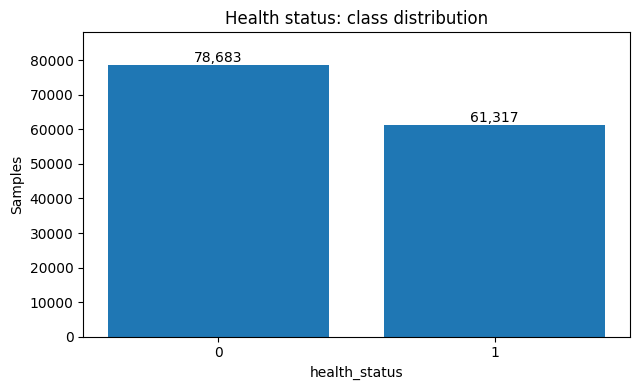

In [2]:
target_counts = train['health_status'].value_counts().sort_index()
print(pd.DataFrame({'count': target_counts, 'ratio': (target_counts / len(train)).round(4)}))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(target_counts.index.astype(str), target_counts.values)
ax.set(title='Health status: class distribution', xlabel='health_status', ylabel='Samples')
for x, y in enumerate(target_counts.values):
    ax.text(x, y + target_counts.max() * 0.012, f'{int(y):,}', ha='center')
ax.set_ylim(0, target_counts.max() * 1.12)
fig.tight_layout()
fig.savefig(fig_dir / 'class_distribution.png', dpi=180, bbox_inches='tight')
plt.show()

## 2. 변수와 타깃의 상관관계

원 데이터의 수치형 변수 중 `index`를 제외하고, `health_status`와의 Pearson 상관계수를 크기순으로 정리합니다. **상관계수가 높다고 해당 변수가 반드시 중요한 예측 변수이거나 인과 요인인 것은 아닙니다.**

iron_lvl           0.4502
stature_inch       0.4465
mass_kg            0.3524
fat_content        0.3310
enzyme_3           0.3065
creatinine         0.2757
chol_good         -0.2692
midsection_inch    0.2640
birth              0.2059
enzyme_2           0.1604
bp_low             0.1105
vision_r           0.1096


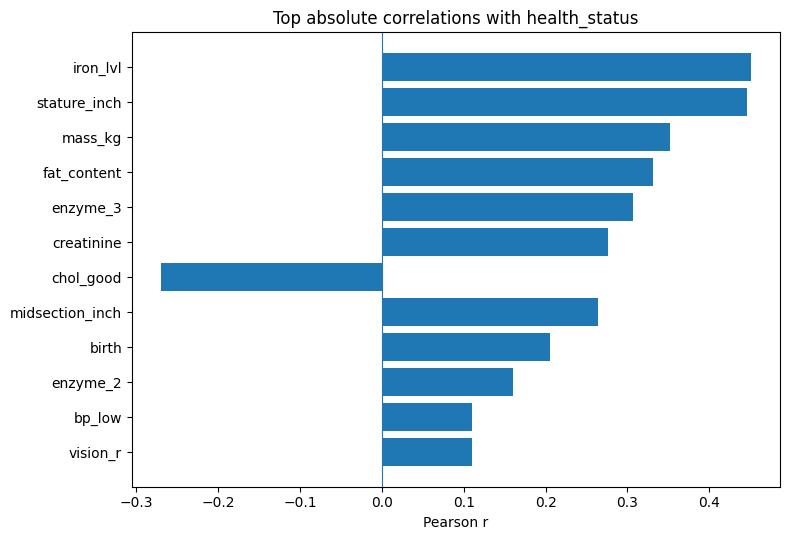

In [3]:
numeric = train.select_dtypes(include='number').drop(columns=['index'], errors='ignore')
correlations = numeric.corr(numeric_only=True)['health_status'].drop('health_status')
top = correlations.reindex(correlations.abs().sort_values(ascending=False).head(12).index)
print(top.round(4).to_string())
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index[::-1], top.values[::-1])
ax.axvline(0, linewidth=0.8)
ax.set(title='Top absolute correlations with health_status', xlabel='Pearson r')
fig.tight_layout()
fig.savefig(fig_dir / 'target_correlations.png', dpi=180, bbox_inches='tight')
plt.show()

## 3. Train/Test 분포 비교

2024년 발표에서는 Train/Test의 상관구조가 전반적으로 유사한 것으로 해석했습니다. 여기에서는 대표 변수 `iron_lvl`, `stature_inch`, `fat_content`의 단변량 분포를 정규화 히스토그램으로 비교합니다. 시각화는 표본 분포 확인용이며, 동일 분포를 통계적으로 증명하지는 않습니다.

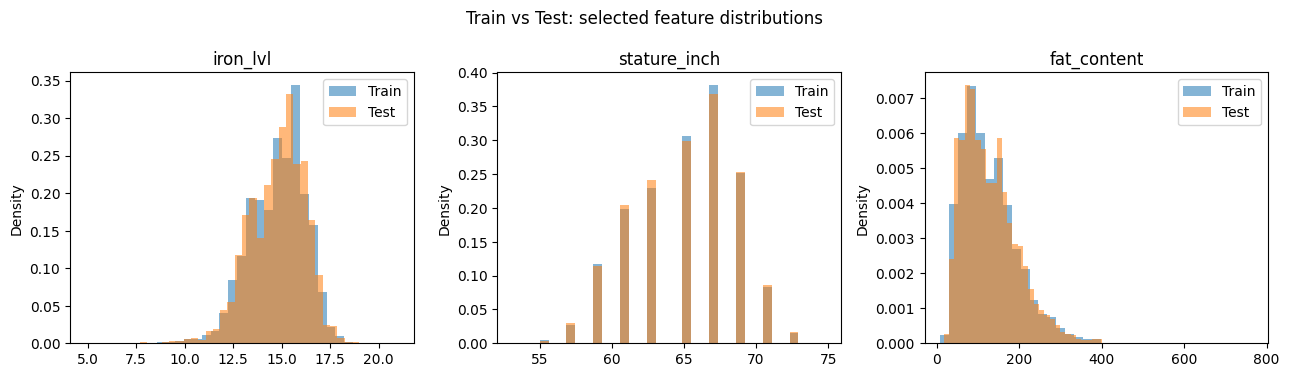

In [4]:
features = ['iron_lvl', 'stature_inch', 'fat_content']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, feature in zip(axes, features):
    ax.hist(train[feature].dropna(), bins=35, density=True, alpha=.55, label='Train')
    ax.hist(test[feature].dropna(), bins=35, density=True, alpha=.55, label='Test')
    ax.set(title=feature, ylabel='Density')
    ax.legend()
fig.suptitle('Train vs Test: selected feature distributions')
fig.tight_layout()
fig.savefig(fig_dir / 'train_test_distributions.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. 분석에서 모델링으로 연결하기

- 클래스별 빈도 차이가 있으므로 검증 시 **ROC-AUC**를 중심으로 보고, 가능하면 stratified CV를 사용하는 방안을 고려합니다.
- 데이터에서 `iron_lvl`, `stature_inch`, `fat_content` 등은 변수 분석의 출발점이 되며, 원 프로젝트에서는 파생 변수와 Feature Selection도 시도했습니다.
- 원본 실험의 일부 파생 변수 계산식에는 단위·괄호를 재검토해야 할 부분이 있으므로, 재현 시 `docs/EXPERIMENT_NOTES.md`를 확인합니다.
- 이 노트북에서 보여준 EDA는 **원 데이터를 다시 분석한 결과**이며, 기존 Kaggle 점수나 모델 성능을 재현한 것은 아닙니다.